In [ ]:
!pip install -q ultralytics kagglehub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.1/46.1 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 40.7 MB/s eta 0:00:00


In [ ]:
import kagglehub

path = kagglehub.dataset_download("viswaprakash1990/garbage-detection")
print("Dataset downloaded to:", path)

100%|██████████| 191M/191M [00:05<00:00, 36.7MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/viswaprakash1990/garbage-detection/versions/1


In [ ]:
import os
import glob
import yaml

# Use the path returned by kagglehub
dataset_root = path

def find_images_dir(split):
    matches = glob.glob(
        os.path.join(dataset_root, "**", split, "images"),
        recursive=True
    )
    return matches[0] if matches else None

train_dir = find_images_dir("train")
val_dir = find_images_dir("valid") or find_images_dir("val")
test_dir = find_images_dir("test")

print("Train:", train_dir)
print("Validation:", val_dir)
print("Test:", test_dir)

data_cfg = {
    "train": train_dir,
    "val": val_dir,
    "test": test_dir,
    "nc": 6,
    "names": [
        "BIODEGRADABLE",
        "CARDBOARD",
        "GLASS",
        "METAL",
        "PAPER",
        "PLASTIC"
    ]
}

fixed_yaml = "/content/garbage_data.yaml"

with open(fixed_yaml, "w") as f:
    yaml.dump(data_cfg, f)

print("Saved:", fixed_yaml)

Train: /root/.cache/kagglehub/datasets/viswaprakash1990/garbage-detection/versions/1/GARBAGE CLASSIFICATION/train/images
Validation: /root/.cache/kagglehub/datasets/viswaprakash1990/garbage-detection/versions/1/GARBAGE CLASSIFICATION/valid/images
Test: /root/.cache/kagglehub/datasets/viswaprakash1990/garbage-detection/versions/1/GARBAGE CLASSIFICATION/test/images
Saved: /content/garbage_data.yaml


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")
model.info()

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
YOLOv8s summary: 129 layers, 11,166,560 parameters, 0 gradients, 28.8 GFLOPs


(129, 11166560, 0, 28.816844800000002)

In [ ]:

results = model.train(
    data=fixed_yaml,
    epochs=75,
    imgsz=640,
    batch=16,
    patience=20,
    pretrained=True,
    workers=2,
    project="runs/detect",
    name="garbage_train"
)

Ultralytics 8.4.105 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/garbage_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=75, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=garbage_train, nbs=64, nms=False, o

Training results saved to:
/content/runs/detect/runs/detect/garbage_train
Ultralytics 8.4.105 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 749.7±438.7 MB/s, size: 19.4 KB)
val: Scanning /root/.cache/kagglehub/datasets/viswaprakash1990/garbage-detection/versions/1/GARBAGE CLASSIFICATION/valid/labels.cache... 2098 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2098/2098 628.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 132/132 3.5it/s 37.7s
                   all       2098      18916      0.622      0.493      0.555       0.38
         BIODEGRADABLE        676      13637      0.825      0.478      0.632      0.358
             CARDBOARD        438       1292      0.759      0.517      0.635      0.483
                 GLASS        805       2380      0.871     

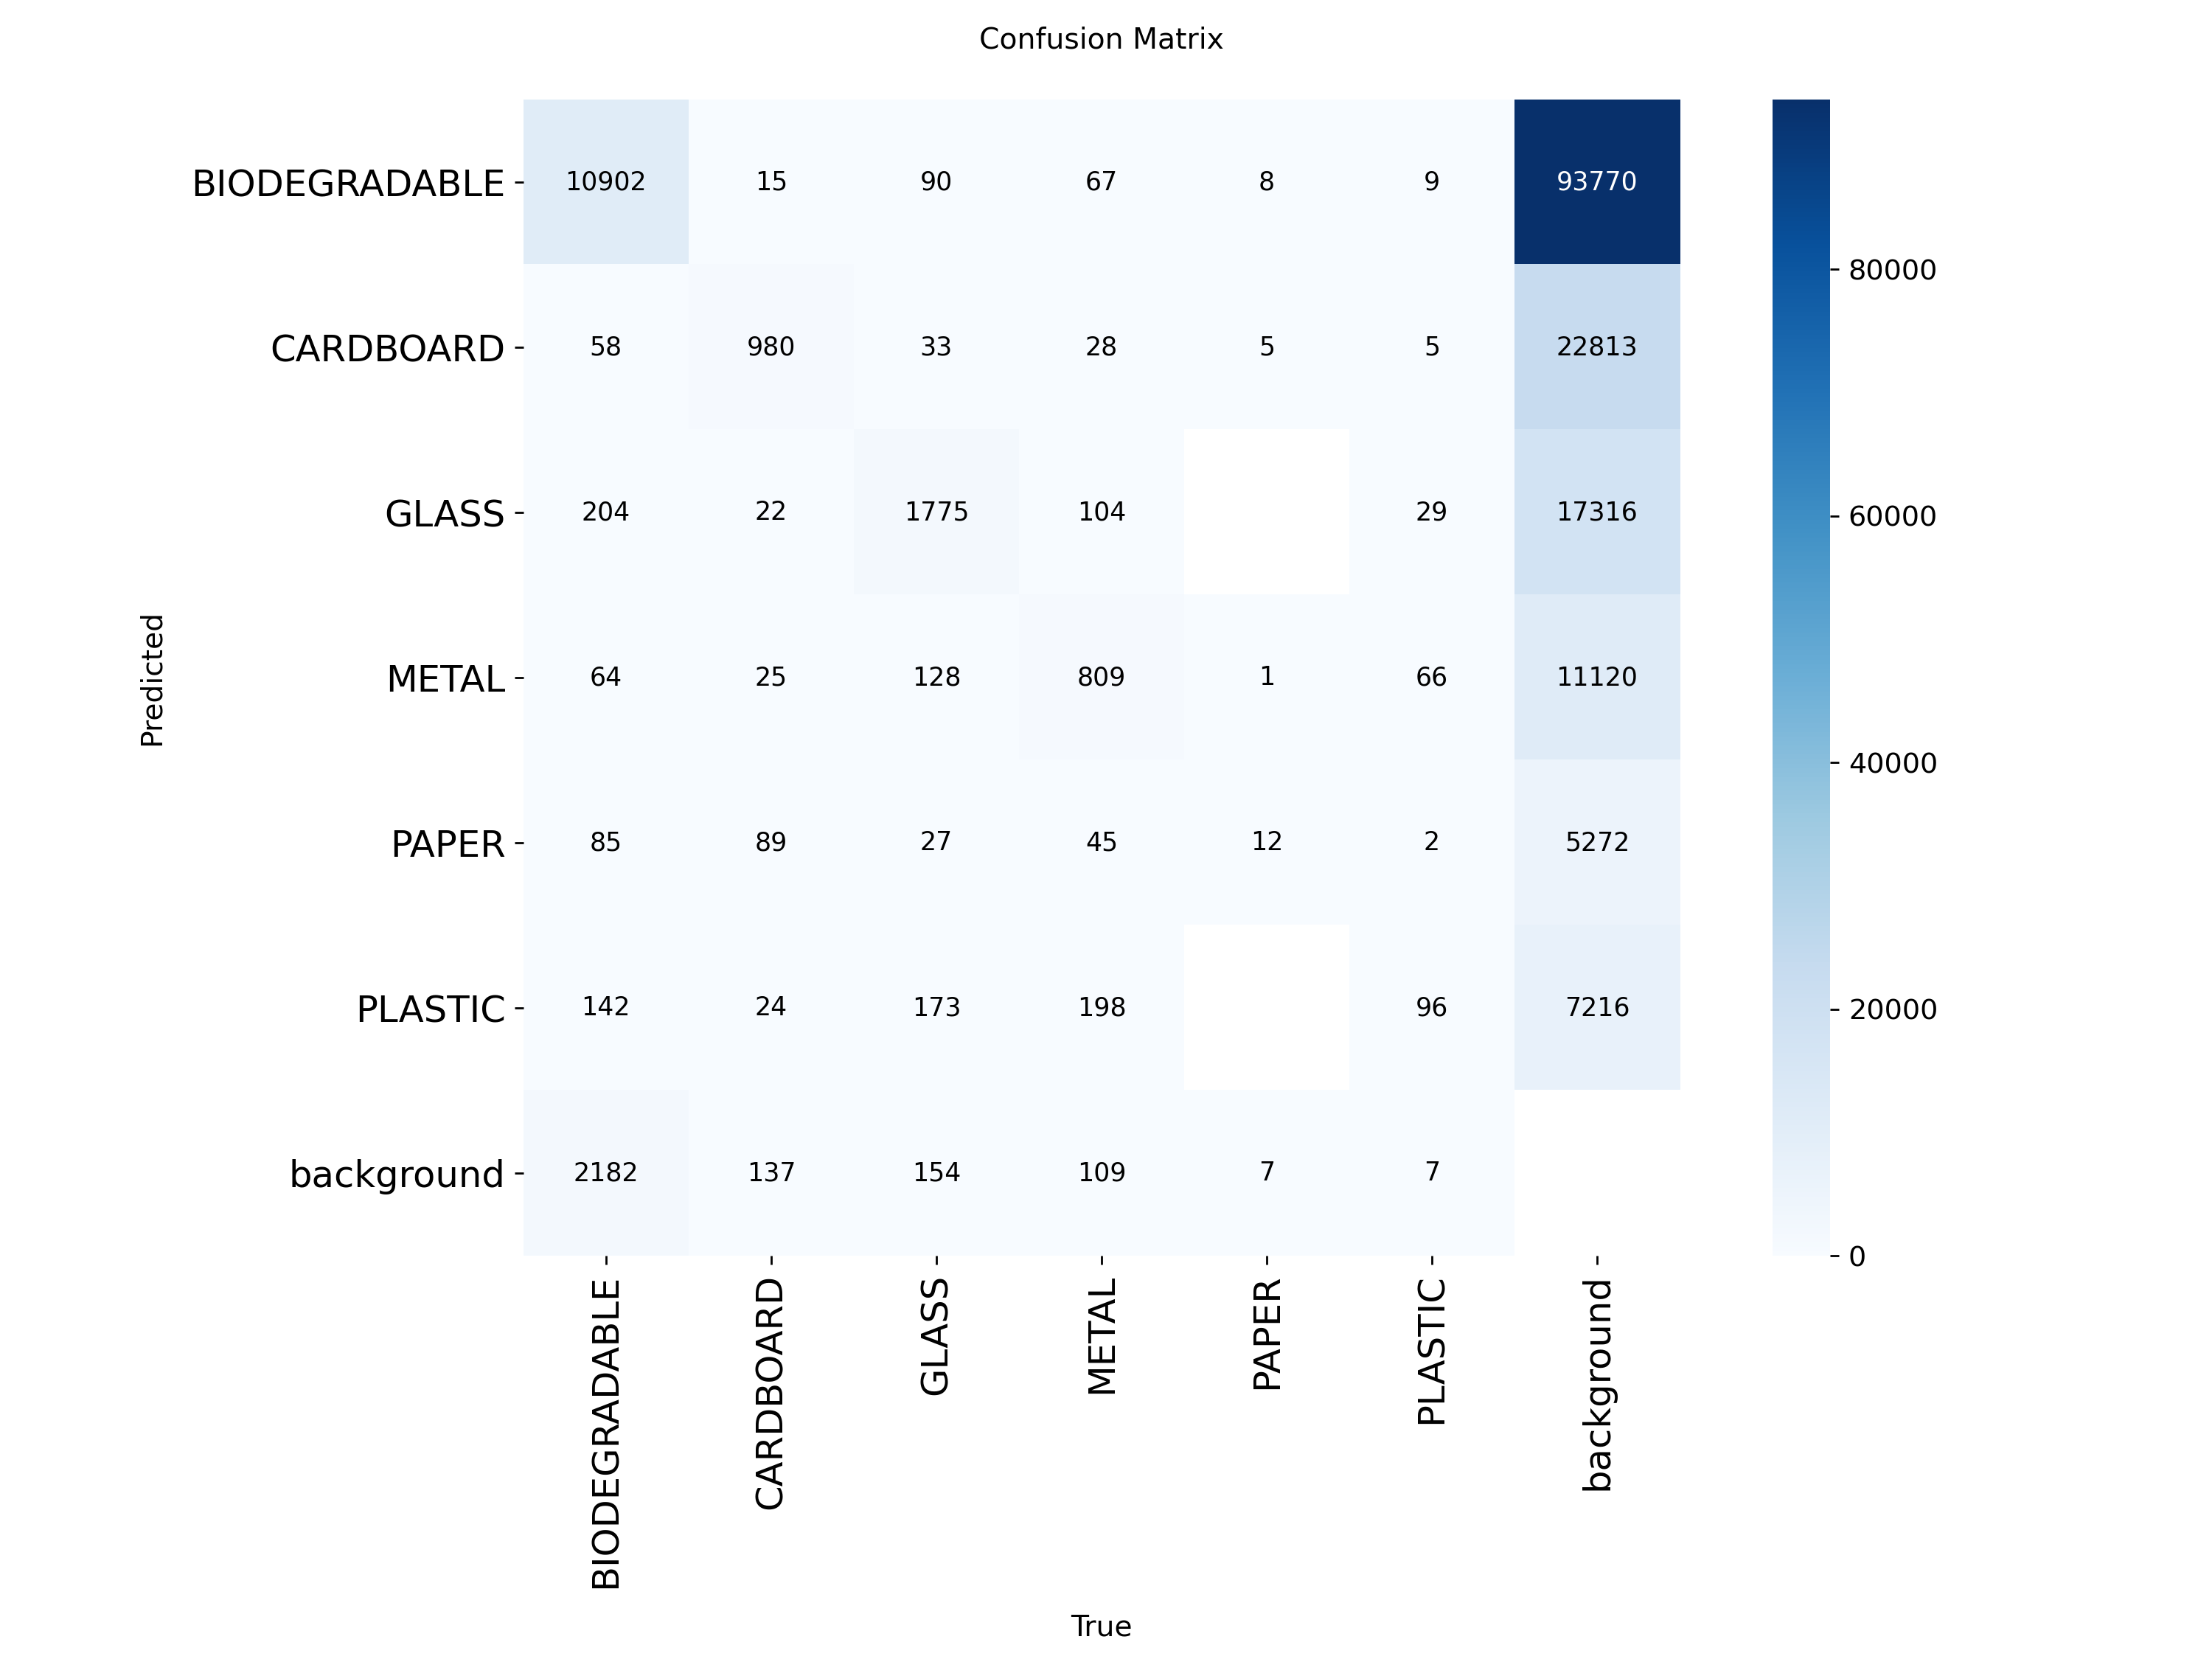

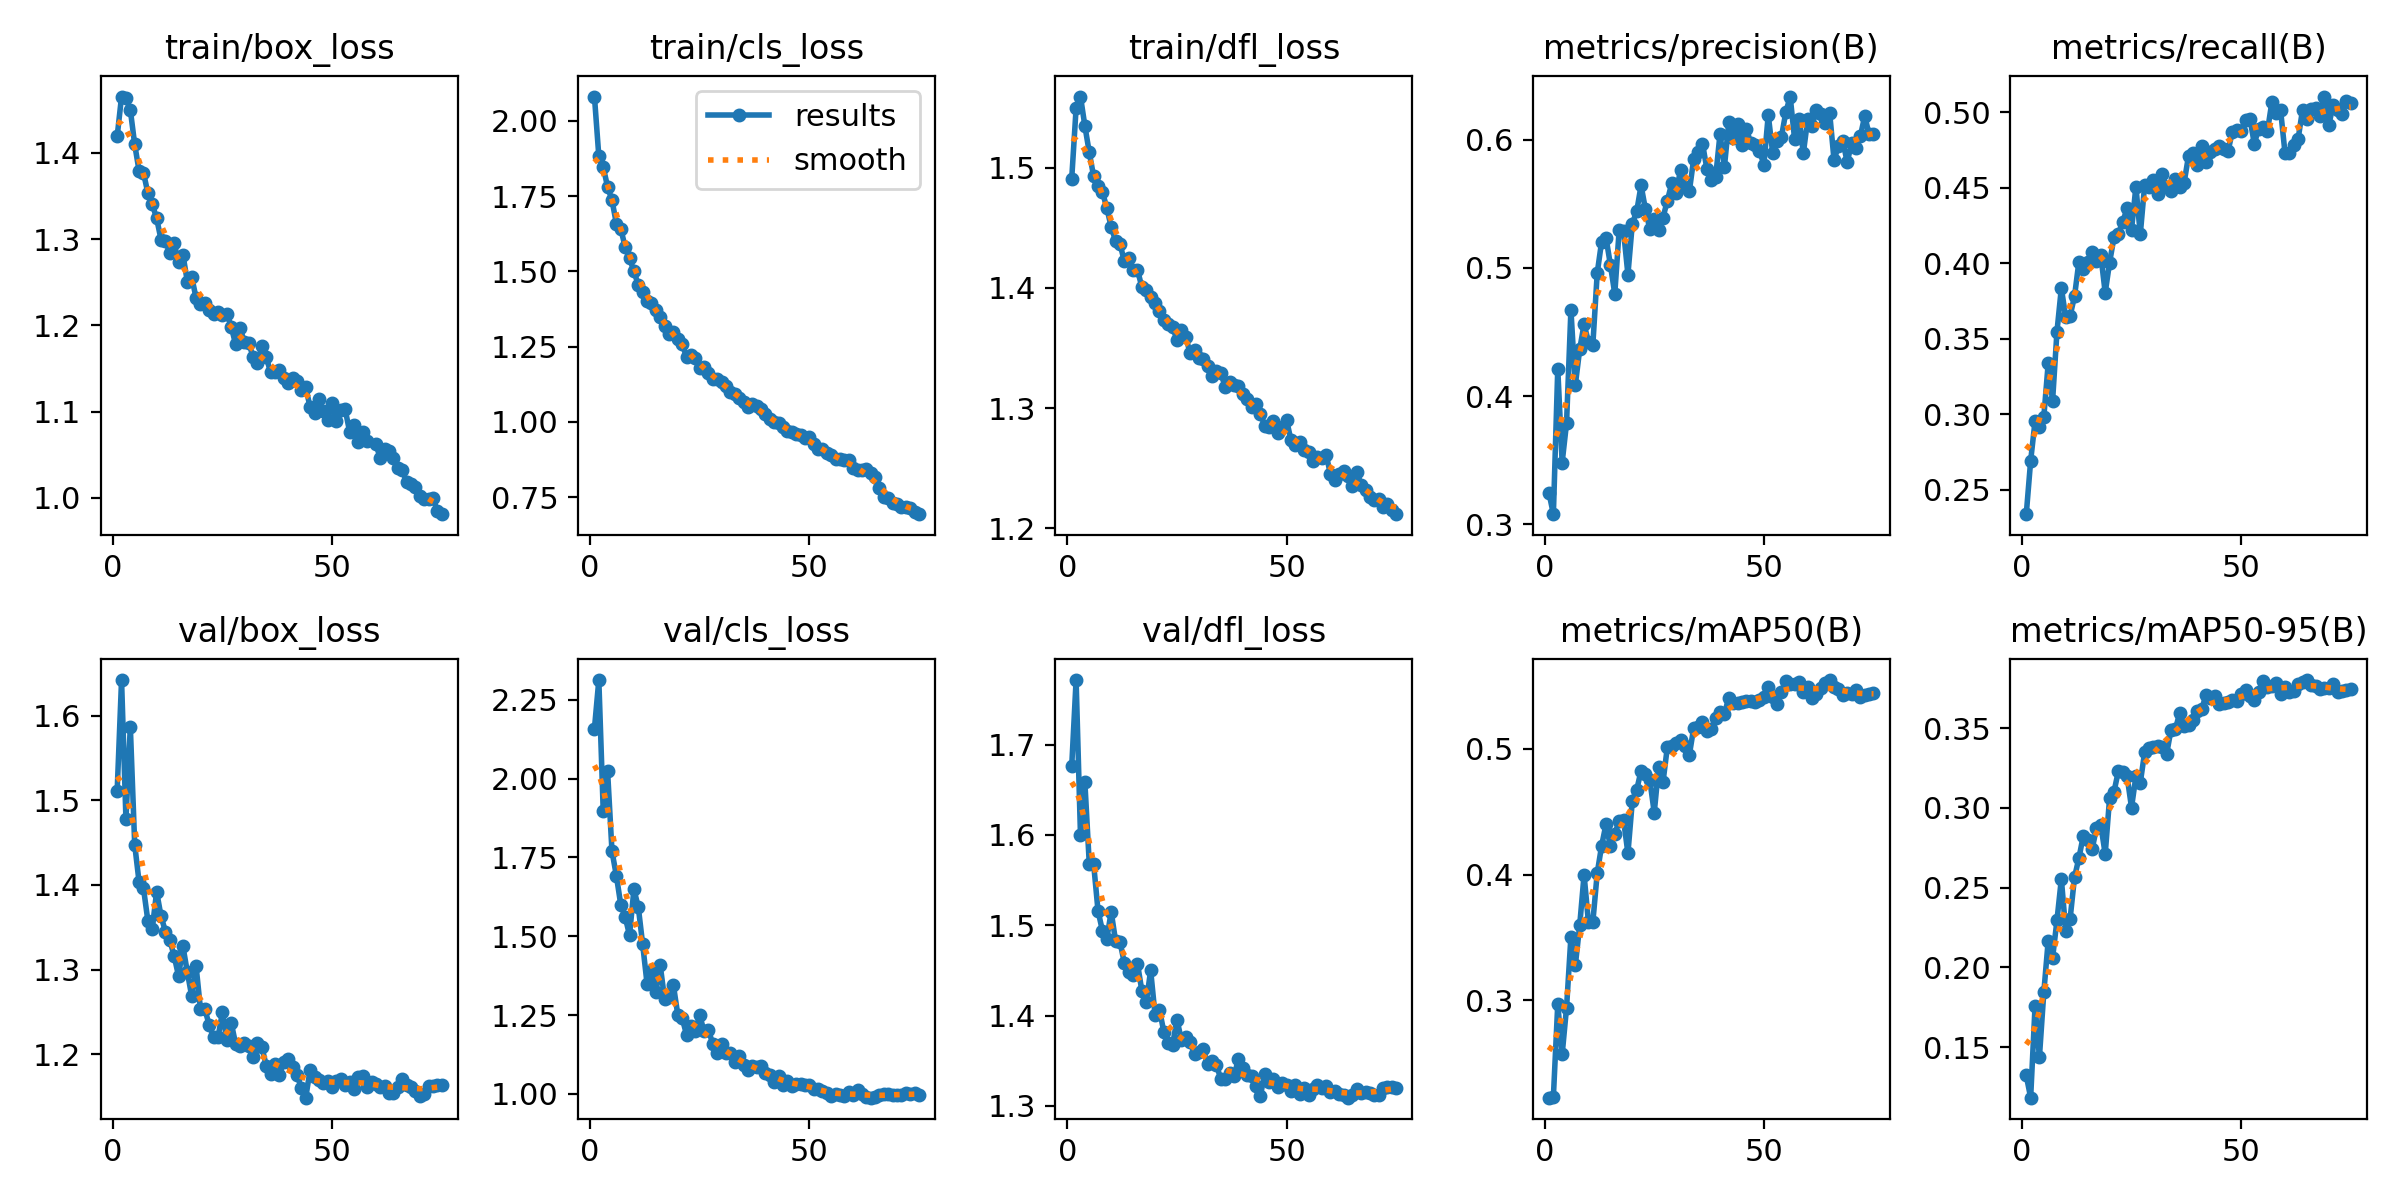

In [ ]:
from ultralytics import YOLO
from IPython.display import Image, display
import os

run_path = results.save_dir

print("Training results saved to:")
print(run_path)

metrics = model.val()

print("\nEvaluation Metrics")
print("-" * 35)
print(f"mAP50      : {metrics.box.map50:.4f}")
print(f"mAP50-95   : {metrics.box.map:.4f}")
print(f"Precision  : {metrics.box.mp:.4f}")
print(f"Recall     : {metrics.box.mr:.4f}")

display(Image(filename=os.path.join(run_path, "confusion_matrix.png"), width=600))
display(Image(filename=os.path.join(run_path, "results.png"), width=700))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Predicting: 1.jpg

image 1/1 /content/drive/MyDrive/waste-test-images/1.jpg: 384x640 2 CARDBOARDs, 1 PLASTIC, 11.4ms
Speed: 1.8ms preprocess, 11.4ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)


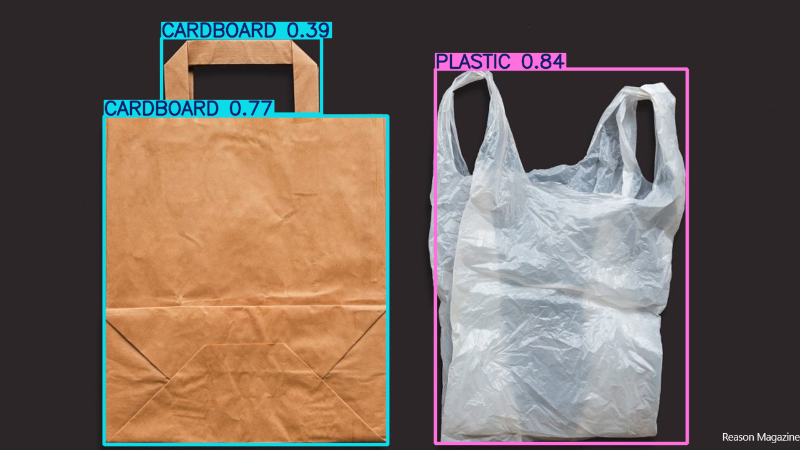

Predicting: 5.jpg

image 1/1 /content/drive/MyDrive/waste-test-images/5.jpg: 640x480 15 BIODEGRADABLEs, 1 METAL, 1 PAPER, 12.9ms
Speed: 3.0ms preprocess, 12.9ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)


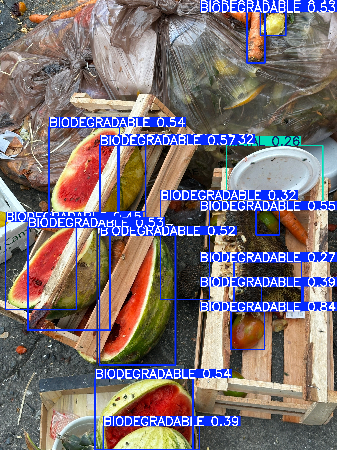

Predicting: 3.webp

image 1/1 /content/drive/MyDrive/waste-test-images/3.webp: 640x608 35 METALs, 1 PLASTIC, 16.8ms
Speed: 3.3ms preprocess, 16.8ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 608)


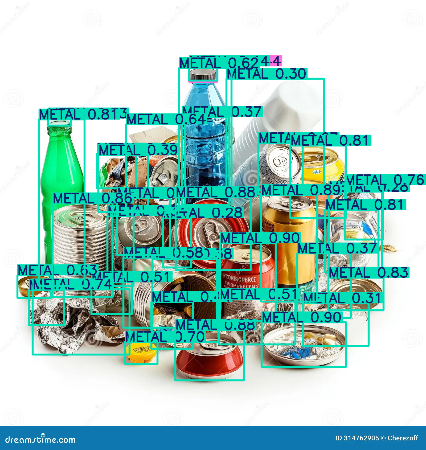

Predicting: 4.jpg

image 1/1 /content/drive/MyDrive/waste-test-images/4.jpg: 448x640 2 GLASSs, 1 PLASTIC, 14.5ms
Speed: 4.3ms preprocess, 14.5ms inference, 2.0ms postprocess per image at shape (1, 3, 448, 640)


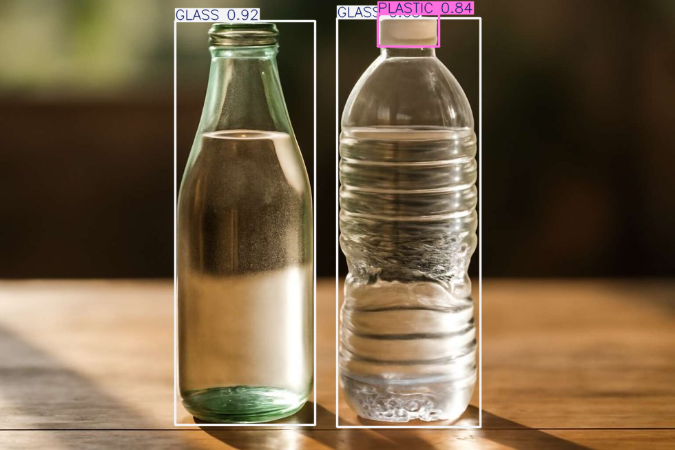

Predicting: 6.jpg

image 1/1 /content/drive/MyDrive/waste-test-images/6.jpg: 448x640 13 CARDBOARDs, 12.7ms
Speed: 3.2ms preprocess, 12.7ms inference, 1.5ms postprocess per image at shape (1, 3, 448, 640)


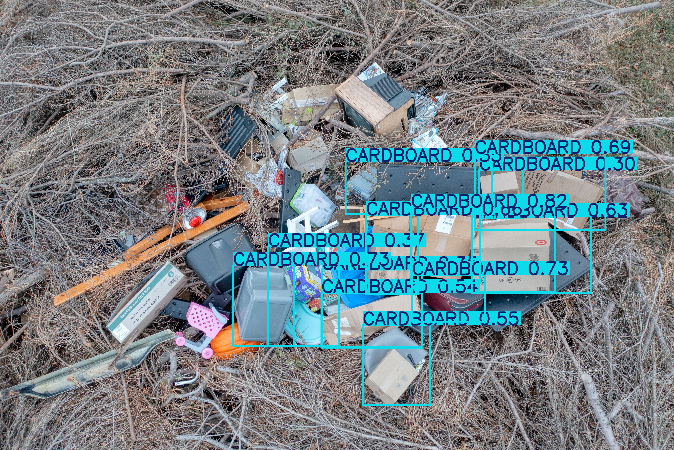

Predicting: 2.png

image 1/1 /content/drive/MyDrive/waste-test-images/2.png: 320x640 1 GLASS, 3 PAPERs, 12.0ms
Speed: 2.8ms preprocess, 12.0ms inference, 1.7ms postprocess per image at shape (1, 3, 320, 640)


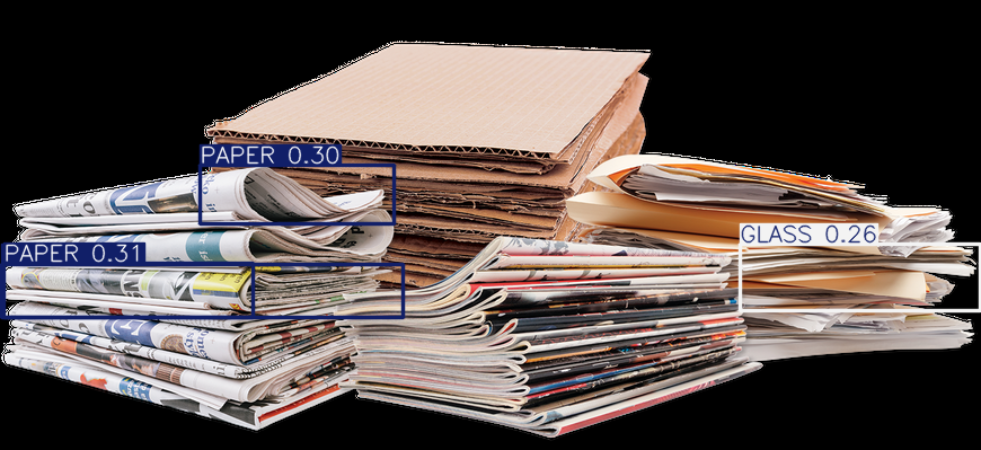

In [ ]:
from ultralytics import YOLO
from google.colab.patches import cv2_imshow

import cv2
import glob
import random
import os

best_model = YOLO(os.path.join(run_path, "weights", "best.pt"))

my_images_dir = "/content/drive/MyDrive/waste-test-images"   # <-- change to your own Drive folder of test photos

image_paths = []

for extension in ("*.jpg", "*.jpeg", "*.png", "*.webp"):
    image_paths.extend(
        glob.glob(os.path.join(my_images_dir, extension))
    )

random.shuffle(image_paths)

sample_images = image_paths[:10]

for image_path in sample_images:

    print(f"Predicting: {os.path.basename(image_path)}")

    prediction = best_model.predict(
        source=image_path,
        conf=0.25,
        save=False
    )

    annotated = prediction[0].plot()

    h, w = annotated.shape[:2]

    display_height = 450
    display_width = int(w * display_height / h)

    annotated = cv2.resize(
        annotated,
        (display_width, display_height)
    )

    cv2_imshow(annotated)